# Lab 7 · Example B — Reuters Topic Classification with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Why a second example?** Same ingredients (Embedding → Bidirectional LSTM → Dense), but now the
task has **46 topic classes**, not 2. This shows how the **output layer and loss change** when you
move from *binary* to *multi-class* classification. Spot the differences from Example A!

| | Example A (IMDB) | Example B (Reuters) |
|---|---|---|
| classes | 2 (pos/neg) | **46 topics** |
| output layer | `Dense(1, 'sigmoid')` | **`Dense(46, 'softmax')`** |
| loss | `binary_crossentropy` | **`sparse_categorical_crossentropy`** |

---
Replace every `None  # TODO (Qn)`. Run top to bottom. *(Downloads the Reuters dataset once.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

Reuters newswires are also pre-encoded as integer indices, each labelled with one of 46 topics.
Keep the top `num_words` words, pad to `maxlen`, and use the built-in test split.

*Hints:* keep 10000 words; pad to 200; count classes with `max(labels)+1`.


In [3]:

num_words = 10000     # Q1a: Keep the 10,000 most frequent words
maxlen = 200          # Q1a: Maximum review length

# Load Reuters dataset
(X_train, y_train), (X_test, y_test) = reuters.load_data(
    num_words=num_words,
    test_split=0.2
)

# Q1b: Pad both training and testing sets
X_train = pad_sequences(X_train, maxlen=maxlen)
X_test  = pad_sequences(X_test, maxlen=maxlen)

# Q1c: Calculate number of topic classes
num_classes = int(max(y_train)) + 1

print("X_train:", X_train.shape, " classes:", num_classes)
# print("X_test: ", X_test.shape)

X_train: (8982, 200)  classes: 46


#### Quick check *(given)*

In [7]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the model (multi-class head)

Same backbone as Example A, but the **output** changes for 46 classes.

*Hints:* `Embedding(num_words, 128)`; `Bidirectional(LSTM(64, return_sequences=False))`;
output is `Dense(num_classes, activation='softmax')` — one neuron per topic.


In [5]:

model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(
    LSTM(64, return_sequences=False)
))

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** Compare this `model.summary()` with Example A. Which layer changed size,
and why? (Hint: look at the final Dense layer's parameter count.)

> **Your answer (Q2d):** the Dense layer grew from (128+1)×1 to (128+1)×46 because ____.


## Task 3 — Compile and train (multi-class loss)

Labels here are **integers** (0–45), not one-hot — so use **`sparse_categorical_crossentropy`**
(it one-hots internally). Optimiser `adam`, track accuracy. Train ~10 epochs, batch 64, with a
20% validation split.


In [6]:

# Q3a) Compile for integer multi-class labels
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Q3b) Train with a validation split
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 54s 454ms/step - accuracy: 0.4214 - loss: 2.3754 - val_accuracy: 0.4747 - val_loss: 1.8751
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 51s 451ms/step - accuracy: 0.5268 - loss: 1.8333 - val_accuracy: 0.5626 - val_loss: 1.7161
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 83s 464ms/step - accuracy: 0.5498 - loss: 1.7428 - val_accuracy: 0.5570 - val_loss: 1.6866
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 51s 453ms/step - accuracy: 0.5897 - loss: 1.6041 - val_accuracy: 0.5838 - val_loss: 1.6456
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 52s 461ms/step - accuracy: 0.6180 - loss: 1.4763 - val_accuracy: 0.5938 - val_loss: 1.5348
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 51s 455ms/step - accuracy: 0.6511 - loss: 1.3210 - val_accuracy: 0.6155 - val_loss: 1.4920
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 49s 433ms/step - accuracy: 0.7066 - loss: 1.1504 - val_accuracy: 0.6427 - val_loss: 1.4662
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 51s 448ms/step - accuracy: 0.7438 - loss: 1

## Task 4 — Evaluate and plot *(fill the blanks)*

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.6607 - loss: 1.4862
Test accuracy: 66.07%


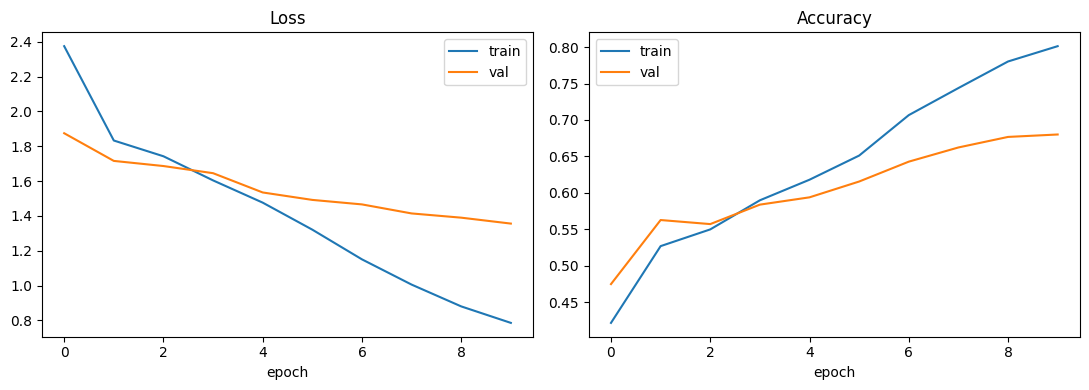

In [8]:

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~65-72%

# Plot training and validation graphs
plt.figure(figsize=(11,4))

# Q4(a): Loss graph
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss')
plt.xlabel('epoch')
plt.legend()

# Q4(b): Accuracy graph
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.xlabel('epoch')
plt.legend()

plt.tight_layout()
plt.show()


## Task 5 — Inspect a prediction *(fill the blank)*

For multi-class, the prediction is the class with the **highest** softmax probability.


In [9]:

# Predict probabilities for the first 5 test articles
probs = model.predict(X_test[:5], verbose=0)  # shape (5, 46)

# Q5) Pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)

# Compare actual and predicted topics
for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")


true topic:  3   predicted:  3
true topic: 10   predicted: 13
true topic:  1   predicted: 24
true topic:  4   predicted:  4
true topic:  4   predicted: 13


### Task 6 Answers:

1. **Three differences:**
   - **Output units:** Example A has 1 output unit, while Example B has 46.
   - **Activation function:** Example A uses `sigmoid` for binary classification, whereas Example B uses `softmax` for multi-class classification.
   - **Loss function:** Example A uses `binary_crossentropy`, while Example B uses `sparse_categorical_crossentropy`.

2. **Why sparse categorical crossentropy?**
   - Because the target labels are formatted as integers (ranging from 0 to 45) rather than one-hot encoded vectors. `sparse_categorical_crossentropy` handles integer targets directly without requiring manual one-hot encoding conversion.

3. **Identical sequence backbone:**
   - This demonstrates that sequence-processing backbones (like Embedding and Bidirectional LSTM) are highly reusable across different downstream tasks. They act as feature extractors that learn the syntax and sequential representations of language, and only the final classification head needs to be adapted for specific tasks.

4. **Why 46-way is harder than 2-way:**
   - In 2-way classification (e.g., IMDB), a random guess has a 50% probability of success. In 46-way classification, a random guess has only ~2.17% chance. Furthermore, with 46 topics, the boundary between classes is much finer, and some topics might share very similar vocabulary and context (e.g., copper vs. gold), making distinction significantly more challenging.

## Task 6 — Short questions *(write answers here)*

1. What are the **three** differences between this model and Example A (output units, activation,
   loss)?
2. Why `sparse_categorical_crossentropy` here instead of `categorical_crossentropy`? (Hint: are
   the labels one-hot or integers?)
3. The Embedding and Bidirectional LSTM layers are **identical** to Example A. What does that tell
   you about reusing a sequence backbone across tasks?
4. Multi-class accuracy (~68%) is lower than IMDB (~87%). Give one reason why 46-way is harder than
   2-way.

> **Your answers:** 1. … 2. … 3. … 4. …
